# Early Intervention Claims Triaging System: EDA and Baseline Model

Capstone Project - Module 20 Initial Report

## Research question

Can early-stage workers compensation claims data reliably predict which claims
will escalate into high-cost outcomes, so they can be flagged as high risk or
low risk soon after they are filed?

## About this notebook

This notebook performs exploratory data analysis (EDA) on workers compensation
claims and builds one baseline machine learning model (Logistic Regression) that
classifies each claim as high risk or low risk. The baseline will be compared
against additional models in the next module.

The dataset is the Kaggle Actuarial Loss Prediction dataset. Each row is a single
claim and includes claimant attributes, job attributes, a short text description
of the injury, the insurer initial cost estimate, and the final total claim cost
(UltimateIncurredClaimCost). The final cost is used only to build the target label
and is removed from the model inputs to avoid leakage.

## Steps in this notebook

1. Setup and imports
2. Load the data
3. Initial data overview
4. Data cleaning: missing values and duplicates
5. Outlier analysis
6. Feature engineering
7. Exploratory data analysis
8. Prepare data for modeling
9. Baseline model: Logistic Regression
10. Model evaluation
11. Summary of findings


## 1. Setup and imports

We import the libraries used for data handling, visualization, and modeling, and
set a few display and plotting defaults. Each library is given its standard alias.

In [2]:
# Data handling
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Modeling and evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    recall_score,
    ConfusionMatrixDisplay,
)

# Display and plotting defaults
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titlesize"] = 12

# One random seed used everywhere for reproducibility
RANDOM_STATE = 42

## 2. Load the data

The notebook expects the file train.csv inside the data folder.

In [4]:
# Load the claims data
df = pd.read_csv("./data/train.csv")
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

Rows: 54000 | Columns: 15


,ClaimNumber,DateTimeOfAccident,DateReported,Age,Gender,MaritalStatus,DependentChildren,DependentsOther,WeeklyWages,PartTimeFullTime,HoursWorkedPerWeek,DaysWorkedPerWeek,ClaimDescription,InitialIncurredCalimsCost,UltimateIncurredClaimCost
0,WC8285054,2002-04-09T07:00:00Z,2002-07-05T00:00:00Z,48,M,M,0,0,500.00,F,38.0,5,LIFTING TYRE INJURY TO RIGHT ARM AND WRIST INJURY,1500,4748.203388
1,WC6982224,1999-01-07T11:00:00Z,1999-01-20T00:00:00Z,43,F,M,0,0,509.34,F,37.5,5,STEPPED AROUND CRATES AND TRUCK TRAY FRACTURE ...,5500,6326.285819
2,WC5481426,1996-03-25T00:00:00Z,1996-04-14T00:00:00Z,30,M,U,0,0,709.10,F,38.0,5,CUT ON SHARP EDGE CUT LEFT THUMB,1700,2293.949087
3,WC9775968,2005-06-22T13:00:00Z,2005-07-22T00:00:00Z,41,M,S,0,0,555.46,F,38.0,5,DIGGING LOWER BACK LOWER BACK STRAIN,15000,17786.487170
4,WC2634037,1990-08-29T08:00:00Z,1990-09-27T00:00:00Z,36,M,M,0,0,377.10,F,38.0,5,REACHING ABOVE SHOULDER LEVEL ACUTE MUSCLE STR...,2800,4014.002925


## 3. Initial data overview

Before any cleaning we look at the structure of the data: column types, summary
statistics, and missing values. This tells us what needs to be fixed.

In [11]:
# Column names, non null counts, and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54000 entries, 0 to 53999
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ClaimNumber                54000 non-null  object 
 1   DateTimeOfAccident         54000 non-null  object 
 2   DateReported               54000 non-null  object 
 3   Age                        54000 non-null  int64  
 4   Gender                     54000 non-null  object 
 5   MaritalStatus              53971 non-null  object 
 6   DependentChildren          54000 non-null  int64  
 7   DependentsOther            54000 non-null  int64  
 8   WeeklyWages                54000 non-null  float64
 9   PartTimeFullTime           54000 non-null  object 
 10  HoursWorkedPerWeek         54000 non-null  float64
 11  DaysWorkedPerWeek          54000 non-null  int64  
 12  ClaimDescription           54000 non-null  object 
 13  InitialIncurredCalimsCost  54000 non-null  int

In [12]:
# Summary statistics for the numeric columns
df.describe(include="number").T

,count,mean,std,min,25%,50%,75%,max
Age,54000.0,33.842370,12.122165,13.000000,23.000000,32.00000,43.000000,81.000
DependentChildren,54000.0,0.119185,0.517780,0.000000,0.000000,0.00000,0.000000,9.000
DependentsOther,54000.0,0.009944,0.109348,0.000000,0.000000,0.00000,0.000000,5.000
WeeklyWages,54000.0,416.364807,248.638669,1.000000,200.000000,392.20000,500.000000,7497.000
HoursWorkedPerWeek,54000.0,37.735084,12.568704,0.000000,38.000000,38.00000,40.000000,640.000
DaysWorkedPerWeek,54000.0,4.905759,0.552129,1.000000,5.000000,5.00000,5.000000,7.000
InitialIncurredCalimsCost,54000.0,7841.146019,20584.075006,1.000000,700.000000,2000.00000,9500.000000,2000000.000
UltimateIncurredClaimCost,54000.0,11003.369169,33390.991292,121.886805,926.338449,3371.24173,8197.248648,4027135.935


In [13]:
# Summary of the categorical (object) columns
df.describe(include="object").T

,count,unique,top,freq
ClaimNumber,54000,54000,WC8285054,1
DateTimeOfAccident,54000,36673,1991-02-19T11:00:00Z,9
DateReported,54000,6653,2001-03-29T00:00:00Z,25
Gender,54000,3,M,41660
MaritalStatus,53971,3,S,26161
PartTimeFullTime,54000,2,F,49112
ClaimDescription,54000,28114,SLIPPED ON ROLLER TENDONITIS RIGHT SHOULDER,289


In [14]:
# Count missing values per column, showing only columns that have any
missing = df.isna().sum()
missing[missing > 0].sort_values(ascending=False)

,0
MaritalStatus,29


Observations from the overview:

- DateTimeOfAccident and DateReported are stored as text and need to be converted
  to datetime so we can compute the reporting delay.
- MaritalStatus has some missing values that need to be handled.
- Age contains a few values of 0, which are not valid ages and should be treated
  as missing.
- UltimateIncurredClaimCost is strongly right skewed, which is expected because a
  small number of claims are very expensive. This is the pattern our project is
  built around.

## 4. Data cleaning: missing values and duplicates

We fix the issues found above: remove duplicate rows, convert the date columns,
treat invalid ages as missing and impute them, and fill missing categorical
values. The cleaning is kept simple and transparent.

In [15]:
# Remove exact duplicate rows (for example data-entry errors)
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Removed", before - len(df), "duplicate rows. Remaining rows:", len(df))

Removed 0 duplicate rows. Remaining rows: 54000


In [17]:
# Convert the two date columns from text to datetime
df["DateTimeOfAccident"] = pd.to_datetime(df["DateTimeOfAccident"], utc=True)
df["DateReported"] = pd.to_datetime(df["DateReported"], utc=True)

# An age of 0 is not valid, so treat it as missing and impute with the median age
df["Age"] = df["Age"].replace(0, np.nan)
median_age = df["Age"].median()
df["Age"] = df["Age"].fillna(median_age).astype(int)

# Impute missing marital status with the most common category (the mode)
most_common_marital = df["MaritalStatus"].mode()[0]
df["MaritalStatus"] = df["MaritalStatus"].fillna(most_common_marital)

print("Remaining missing values after cleaning:", int(df.isna().sum().sum()))

Remaining missing values after cleaning: 0


## 5. Outlier analysis

Outliers matter in this project because the most expensive claims are exactly the
cases we want to flag. We use the interquartile range (IQR) rule to identify
unusually large values in the continuous variables, then make a deliberate choice
about each one rather than deleting blindly.

In [18]:
def iqr_outlier_count(series):
    # Count values that fall outside 1.5 times the IQR from the quartiles
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    mask = (series < low) | (series > high)
    return int(mask.sum()), round(low, 2), round(high, 2)

continuous_cols = ["Age", "WeeklyWages", "HoursWorkedPerWeek",
                   "InitialIncurredCalimsCost", "UltimateIncurredClaimCost"]

# Build a small summary table of outlier counts and bounds per column
rows = []
for col in continuous_cols:
    count, low, high = iqr_outlier_count(df[col])
    rows.append({"column": col, "outliers": count,
                 "lower_bound": low, "upper_bound": high})
outlier_summary = pd.DataFrame(rows)
outlier_summary

,column,outliers,lower_bound,upper_bound
0,Age,22,-7.00,73.00
1,WeeklyWages,1478,-250.00,950.00
2,HoursWorkedPerWeek,7446,35.00,43.00
3,InitialIncurredCalimsCost,4355,-12500.00,22700.00
4,UltimateIncurredClaimCost,6805,-9980.03,19103.61


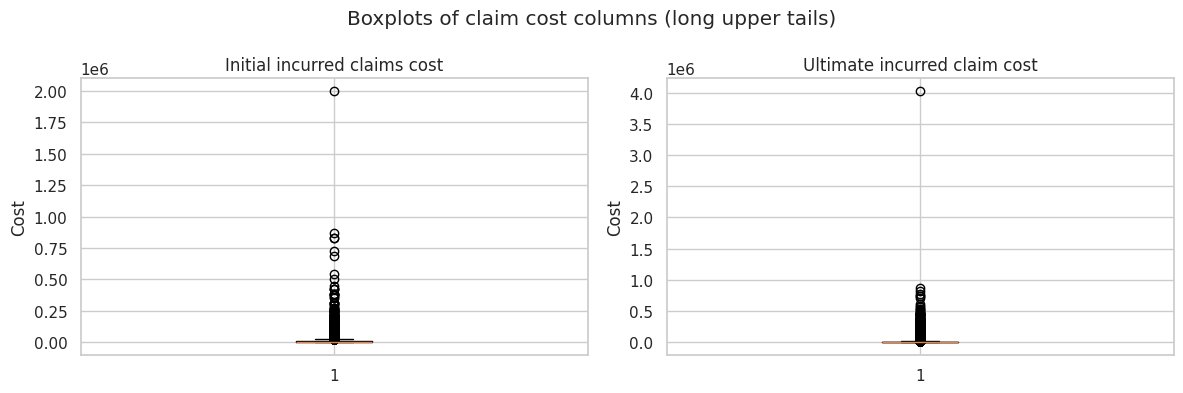

In [19]:
# Visualize the spread and outliers of the two cost columns with boxplots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot(df["InitialIncurredCalimsCost"], vert=True)
axes[0].set_title("Initial incurred claims cost")
axes[0].set_ylabel("Cost")
axes[1].boxplot(df["UltimateIncurredClaimCost"], vert=True)
axes[1].set_title("Ultimate incurred claim cost")
axes[1].set_ylabel("Cost")
fig.suptitle("Boxplots of claim cost columns (long upper tails)")
plt.tight_layout()
plt.show()

Decisions from the outlier analysis:

- The cost columns have long upper tails. These high values are genuine expensive
  claims and are the signal our project is built on, so we keep them rather than
  remove them. Removing them would throw away the high risk cases.
- WeeklyWages has a few extreme values that are likely data errors. We cap
  (winsorize) it at the 1st and 99th percentiles so a handful of extreme points do
  not distort the model, while keeping every row.

In [20]:
# Winsorize weekly wages to the 1st and 99th percentiles
low_cap = df["WeeklyWages"].quantile(0.01)
high_cap = df["WeeklyWages"].quantile(0.99)
df["WeeklyWages"] = df["WeeklyWages"].clip(lower=low_cap, upper=high_cap)
print("WeeklyWages capped to range [{:.2f}, {:.2f}]".format(low_cap, high_cap))

WeeklyWages capped to range [42.00, 1237.52]


## 6. Feature engineering

We build features that are known early in the life of a claim, at or near the time
it is reported. These are the inputs the model is allowed to use.

Engineered features:

- reporting_lag_days: days between the accident and the date it was reported.
- accident_month and accident_dayofweek: timing of the accident.
- total_dependents: dependent children plus other dependents.
- desc_word_count: number of words in the claim description.
- body_part: the body part named in the claim description.
- injury keyword flags: indicators for severe injury words in the description.

We also build the target. There is no ready made high risk column, so we define it
by thresholding the final claim cost at the 90th percentile. Claims above that
threshold are labelled high risk. The cost column itself is removed from the model
inputs later so it cannot leak into the prediction.

In [22]:
# Reporting lag in days (clip negatives that could come from data errors)
df["reporting_lag_days"] = (df["DateReported"] - df["DateTimeOfAccident"]).dt.days
df["reporting_lag_days"] = df["reporting_lag_days"].clip(lower=0)

# Accident timing features
df["accident_month"] = df["DateTimeOfAccident"].dt.month
df["accident_dayofweek"] = df["DateTimeOfAccident"].dt.dayofweek

# Combine the two dependent counts into one
df["total_dependents"] = df["DependentChildren"] + df["DependentsOther"]

# Work from an upper case copy of the description for all text features
desc_upper = df["ClaimDescription"].str.upper()

# Number of words in the claim description
df["desc_word_count"] = desc_upper.str.split().str.len()

# Assign a body part by searching the description for known body part words.
# The first match in this priority order is used, otherwise OTHER.
body_parts = ["BACK", "FINGER", "HAND", "WRIST", "ARM", "SHOULDER", "NECK",
              "HEAD", "EYE", "KNEE", "ANKLE", "FOOT", "LEG", "HIP", "THUMB"]

def find_body_part(text):
    for part in body_parts:
        if part in text:
            return part
    return "OTHER"

df["body_part"] = desc_upper.apply(find_body_part)

# Flags for severe injury words, using word stems so variants are captured
# (for example AMPUTAT matches AMPUTATION and AMPUTATED).
severe_stems = ["FRACTURE", "BURN", "CRUSH", "AMPUTAT", "DISLOCAT", "CONCUSS"]
for stem in severe_stems:
    df["kw_" + stem.lower()] = desc_upper.str.contains(stem).astype(int)
df["has_severe_keyword"] = df[["kw_" + s.lower() for s in severe_stems]].max(axis=1)

df[["reporting_lag_days", "accident_month", "total_dependents",
    "desc_word_count", "body_part", "has_severe_keyword"]].head()

,reporting_lag_days,accident_month,total_dependents,desc_word_count,body_part,has_severe_keyword
0,86,4,0,9,WRIST,0
1,12,1,0,9,ARM,1
2,20,3,0,7,THUMB,0
3,29,6,0,6,BACK,0
4,28,8,0,11,SHOULDER,0


In [23]:
# Build the target: high risk if the final cost is in the top 10 percent
threshold = df["UltimateIncurredClaimCost"].quantile(0.90)
df["high_risk"] = (df["UltimateIncurredClaimCost"] >= threshold).astype(int)

print("High risk cost threshold (90th percentile): {:.2f}".format(threshold))
df["high_risk"].value_counts(normalize=True).round(3)

High risk cost threshold (90th percentile): 24005.78


,proportion
high_risk,
0,0.9
1,0.1


The target is imbalanced: about 10 percent of claims are high risk. This is
expected and realistic, and it drives the choice of evaluation metric later in the
notebook.

## 7. Exploratory data analysis

We now explore the data visually. We use bar and count plots for categorical
variables and histograms and boxplots for continuous variables, so each plot type
matches the variable it shows.

### 7.1 Target variable and class balance

A count plot is the right choice for a single categorical outcome.

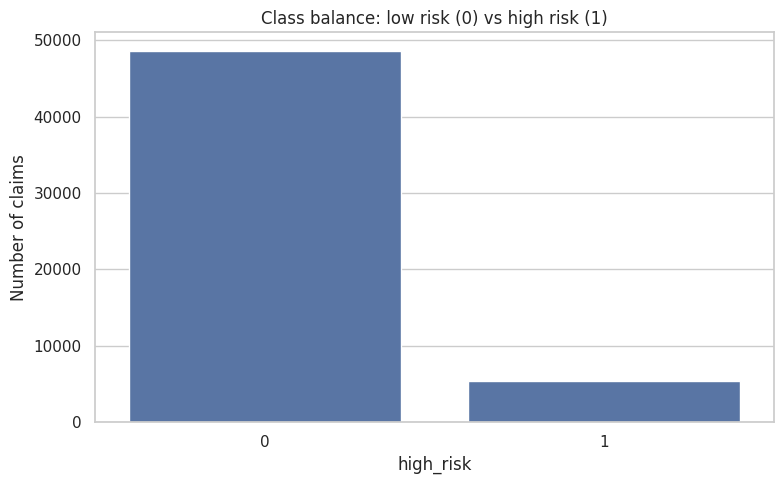

In [24]:
ax = sns.countplot(x="high_risk", data=df)
ax.set_title("Class balance: low risk (0) vs high risk (1)")
ax.set_xlabel("high_risk")
ax.set_ylabel("Number of claims")
plt.tight_layout()
plt.show()

### 7.2 Distribution of the final claim cost

The cost is a continuous, heavy tailed variable, so we use histograms and view it
on a log scale to see the shape clearly. Subplots place the raw and log views side
by side.

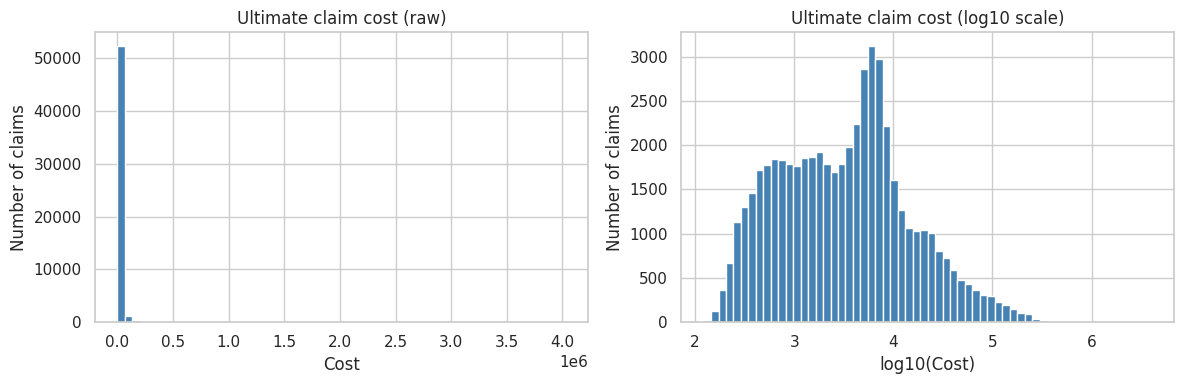

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["UltimateIncurredClaimCost"], bins=60, color="steelblue")
axes[0].set_title("Ultimate claim cost (raw)")
axes[0].set_xlabel("Cost")
axes[0].set_ylabel("Number of claims")

axes[1].hist(np.log10(df["UltimateIncurredClaimCost"]), bins=60, color="steelblue")
axes[1].set_title("Ultimate claim cost (log10 scale)")
axes[1].set_xlabel("log10(Cost)")
axes[1].set_ylabel("Number of claims")
plt.tight_layout()
plt.show()

On the raw scale the cost is dominated by a long right tail. On the log scale
it is close to bell shaped, confirming that a small group of expensive claims
drives the tail. Those are the claims the triage system aims to catch early.

### 7.3 Claimant demographics and risk

A boxplot compares a continuous variable (Age) across the two risk groups, and a
bar plot compares a rate across a categorical variable (Gender).

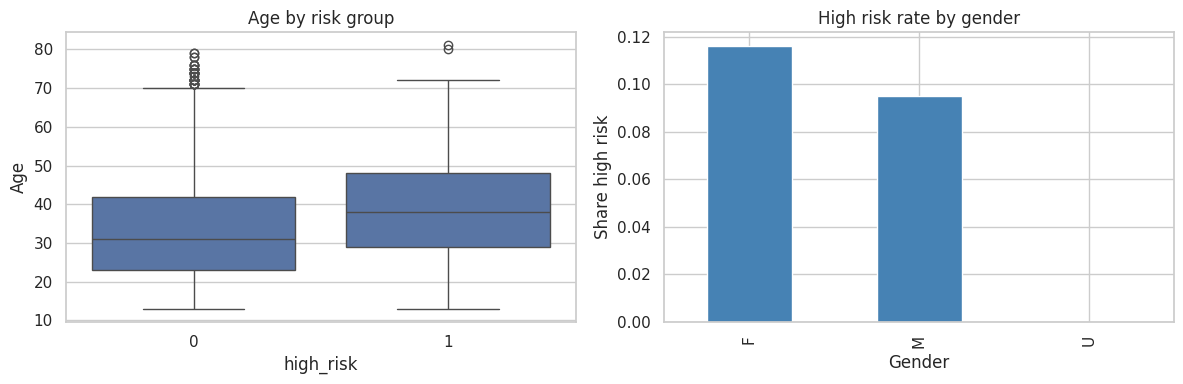

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x="high_risk", y="Age", data=df, ax=axes[0])
axes[0].set_title("Age by risk group")
axes[0].set_xlabel("high_risk")

risk_by_gender = df.groupby("Gender")["high_risk"].mean()
risk_by_gender.plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("High risk rate by gender")
axes[1].set_ylabel("Share high risk")
axes[1].set_xlabel("Gender")
plt.tight_layout()
plt.show()

### 7.4 Wages and employment type

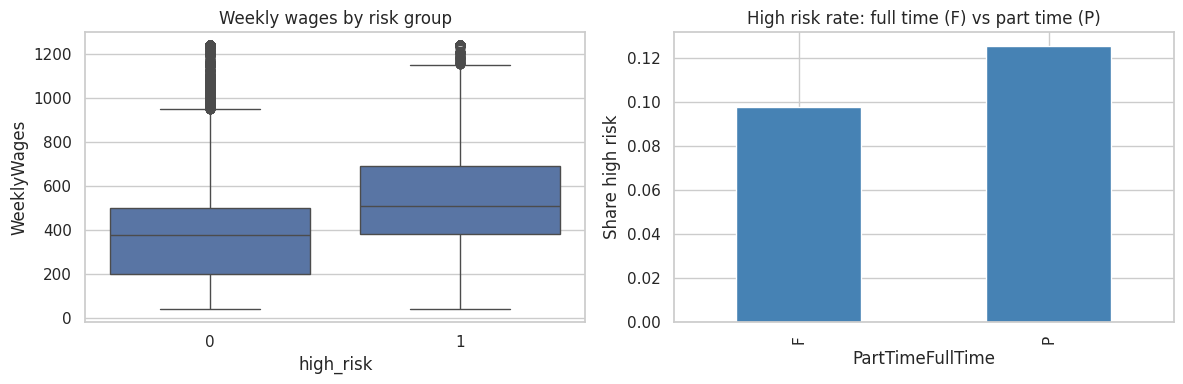

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x="high_risk", y="WeeklyWages", data=df, ax=axes[0])
axes[0].set_title("Weekly wages by risk group")
axes[0].set_xlabel("high_risk")

risk_by_ptft = df.groupby("PartTimeFullTime")["high_risk"].mean()
risk_by_ptft.plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("High risk rate: full time (F) vs part time (P)")
axes[1].set_ylabel("Share high risk")
axes[1].set_xlabel("PartTimeFullTime")
plt.tight_layout()
plt.show()

Higher weekly wages are associated with a higher chance of a high risk claim,
which makes sense because wage replacement is a major cost driver. Full time
workers also show a higher high risk rate than part time workers.

### 7.5 Reporting lag and risk

A core idea of the project is that delay matters, so we compare the reporting delay
between the two risk groups with a boxplot.

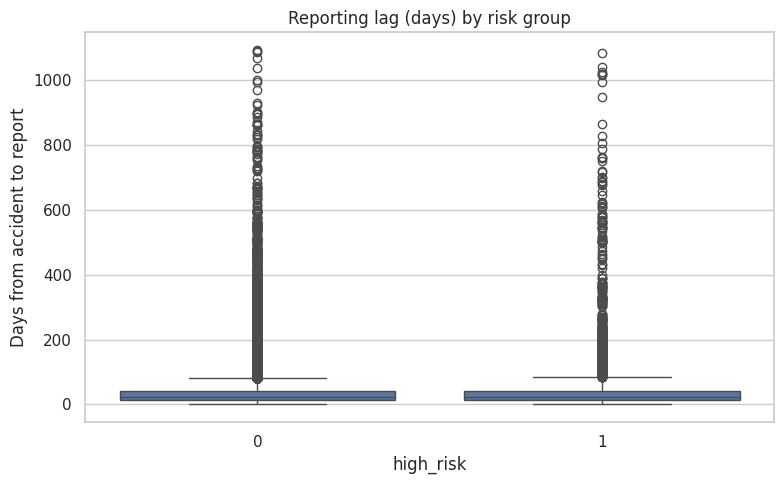

,reporting_lag_days
high_risk,
0,21.0
1,23.0


In [29]:
ax = sns.boxplot(x="high_risk", y="reporting_lag_days", data=df)
ax.set_title("Reporting lag (days) by risk group")
ax.set_xlabel("high_risk")
ax.set_ylabel("Days from accident to report")
plt.tight_layout()
plt.show()

# Median reporting lag for each group
df.groupby("high_risk")["reporting_lag_days"].median()

High risk claims tend to be reported after a longer delay. This supports the
premise that late reporting is an early warning sign worth acting on.

### 7.6 Injury type signals (interactive Plotly chart)

Here we use Plotly to draw an interactive bar chart of the high risk rate by body
part. Hovering over a bar shows the exact rate. This is a categorical variable, so
a bar chart is the appropriate choice.

In [30]:
# High risk rate by body part, sorted from highest to lowest
risk_by_body = (
    df.groupby("body_part")["high_risk"].mean()
    .sort_values(ascending=False)
    .reset_index()
)
risk_by_body.columns = ["body_part", "high_risk_rate"]

fig = px.bar(
    risk_by_body,
    x="body_part",
    y="high_risk_rate",
    title="High risk rate by body part",
    labels={"body_part": "Body part", "high_risk_rate": "Share high risk"},
)
fig.update_layout(width=800, height=450)
fig.show()

### 7.7 Severe injury keyword and risk

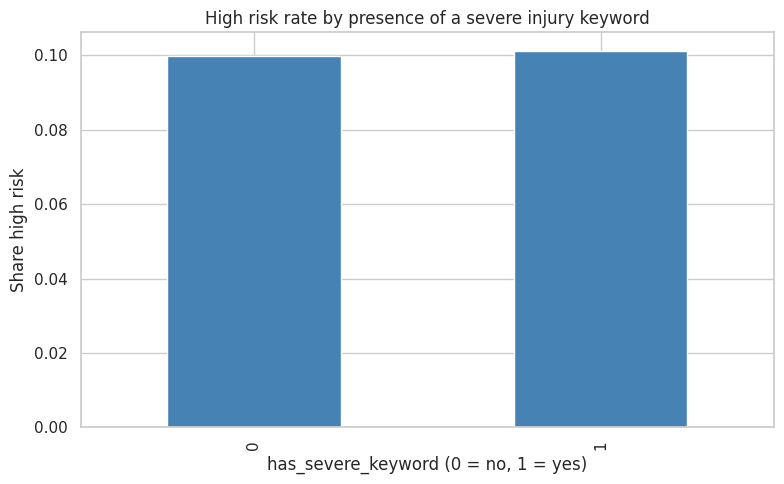

,high_risk
has_severe_keyword,
0,0.100
1,0.101


In [31]:
risk_by_keyword = df.groupby("has_severe_keyword")["high_risk"].mean()
ax = risk_by_keyword.plot(kind="bar", color="steelblue")
ax.set_title("High risk rate by presence of a severe injury keyword")
ax.set_xlabel("has_severe_keyword (0 = no, 1 = yes)")
ax.set_ylabel("Share high risk")
plt.tight_layout()
plt.show()

risk_by_keyword.round(3)

Claims that mention a severe injury word are far more likely to be high risk.
This is one of the strongest early signals and is simple to extract from the claim
description.

### 7.8 Correlation of numeric features

A heatmap summarizes how the numeric features relate to each other and to the
target.

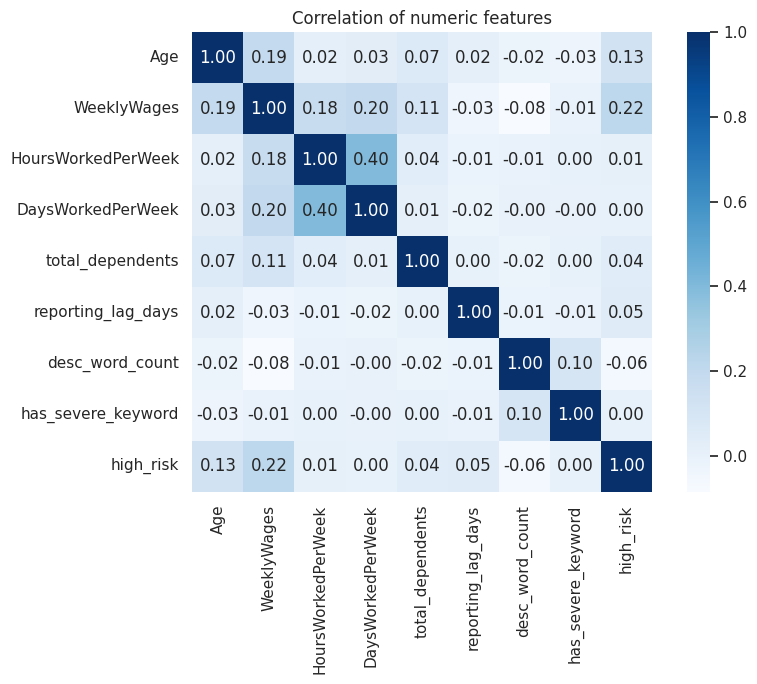

In [32]:
num_cols = ["Age", "WeeklyWages", "HoursWorkedPerWeek", "DaysWorkedPerWeek",
            "total_dependents", "reporting_lag_days", "desc_word_count",
            "has_severe_keyword", "high_risk"]
corr = df[num_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", square=True)
plt.title("Correlation of numeric features")
plt.tight_layout()
plt.show()

The strongest positive relationships with high_risk are the severe injury
keyword flag, weekly wages, and reporting lag. These agree with the single feature
views above and are the signals the baseline model will rely on most.

## 8. Prepare data for modeling

We select only features that are available early in the claim and that do not leak
the answer. We remove:

- UltimateIncurredClaimCost, because it was used to build the target.
- InitialIncurredCalimsCost, because it is the insurer own cost estimate and our
  question is whether claim and claimant attributes alone can flag risk early. It
  can be added in a later model.
- Identifier, raw text, and raw date columns that have already been converted into
  engineered features.

Categorical columns are converted to numeric indicator columns, the data is split
into training and test sets with the class balance preserved, and the features are
scaled so Logistic Regression behaves well.

In [33]:
# Columns that must not go into the model
drop_cols = [
    "ClaimNumber", "DateTimeOfAccident", "DateReported", "ClaimDescription",
    "body_part", "UltimateIncurredClaimCost", "InitialIncurredCalimsCost",
    "high_risk",
]
feature_df = df.drop(columns=drop_cols)

# One hot encode the remaining categorical columns
categorical = ["Gender", "MaritalStatus", "PartTimeFullTime"]
feature_df = pd.get_dummies(feature_df, columns=categorical, drop_first=True)

X = feature_df
y = df["high_risk"]
print("Feature matrix shape:", X.shape)
print("Number of features:", X.shape[1])

Feature matrix shape: (54000, 23)
Number of features: 23


In [34]:
# Split into train and test, keeping the same class balance in both (stratify)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# Scale features so no single feature dominates the linear model
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training rows:", X_train.shape[0], "| Test rows:", X_test.shape[0])

Training rows: 43200 | Test rows: 10800


## 9. Baseline model: Logistic Regression

Logistic Regression is a simple, interpretable linear classifier and a natural
baseline for a binary classification problem. We set class_weight to balanced so
the model pays attention to the minority high risk class despite the imbalance.

In [35]:
# Train the baseline classifier
model = LogisticRegression(
    max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
)
model.fit(X_train_scaled, y_train)

# Predicted labels and predicted probabilities for the positive class
y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]
print("Model trained.")

Model trained.


## 10. Model evaluation

### Evaluation metric: identification and rationale

Primary metric: recall on the high risk class, supported by the area under the ROC
curve (AUC).

Rationale:

- The classes are imbalanced (about 90 percent low risk), so accuracy is
  misleading. A model that labels every claim low risk would score about 90
  percent accuracy while catching no high risk claims at all.
- In early intervention the cost of a false negative (missing a claim that goes on
  to escalate) is much higher than the cost of a false positive (reviewing a claim
  that turns out routine). Recall on the high risk class measures the share of
  truly high risk claims the model catches, which is exactly what matters here.
- AUC measures how well the model ranks claims by risk across all thresholds,
  independent of the specific cut off, so it is a fair single number summary for an
  imbalanced problem.

We report the full classification report for completeness, then focus on recall and
AUC.

In [36]:
# Full report, then the two metrics we focus on
print(classification_report(y_test, y_pred, digits=3))

high_risk_recall = recall_score(y_test, y_pred, pos_label=1)
auc = roc_auc_score(y_test, y_proba)
print("High risk recall: {:.3f}".format(high_risk_recall))
print("ROC AUC: {:.3f}".format(auc))

              precision    recall  f1-score   support

           0      0.947     0.689     0.798      9720
           1      0.189     0.654     0.294      1080

    accuracy                          0.685     10800
   macro avg      0.568     0.671     0.546     10800
weighted avg      0.871     0.685     0.747     10800

High risk recall: 0.654
ROC AUC: 0.731


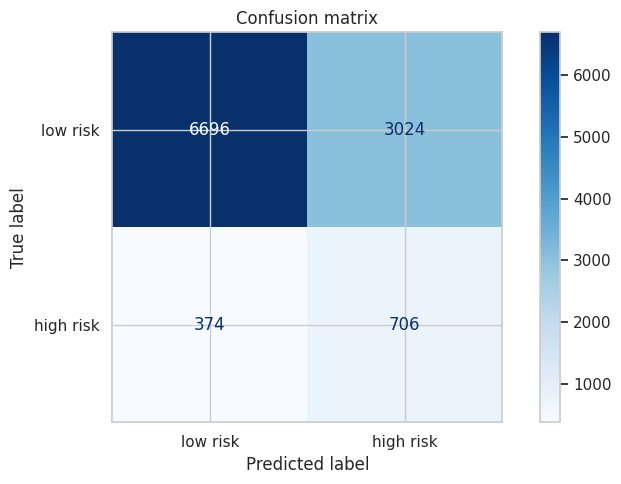

In [37]:
# Confusion matrix shows where the errors fall
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=["low risk", "high risk"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix")
plt.tight_layout()
plt.show()

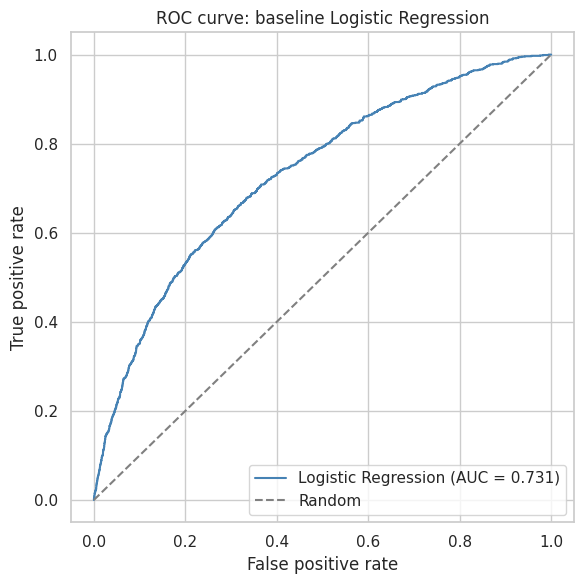

In [38]:
# ROC curve visualizes the ranking quality summarized by AUC
fpr, tpr, _ = roc_curve(y_test, y_proba)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color="steelblue",
         label="Logistic Regression (AUC = {:.3f})".format(auc))
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve: baseline Logistic Regression")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Interpretation of the metric

- The high risk recall tells us the model catches about two thirds of the claims
  that truly escalate. For early intervention this is the key number, because the
  purpose of the system is to not miss the expensive cases.
- The AUC of around 0.73 means that, given one random high risk claim and one
  random low risk claim, the model ranks the high risk one as more risky about 73
  percent of the time. This is above 0.5, the score of random guessing.
- The trade off is lower precision on the high risk class: some claims flagged as
  high risk turn out routine. In this setting that is acceptable, because a flagged
  claim simply receives a closer review, whereas a missed high risk claim loses the
  chance for early intervention.

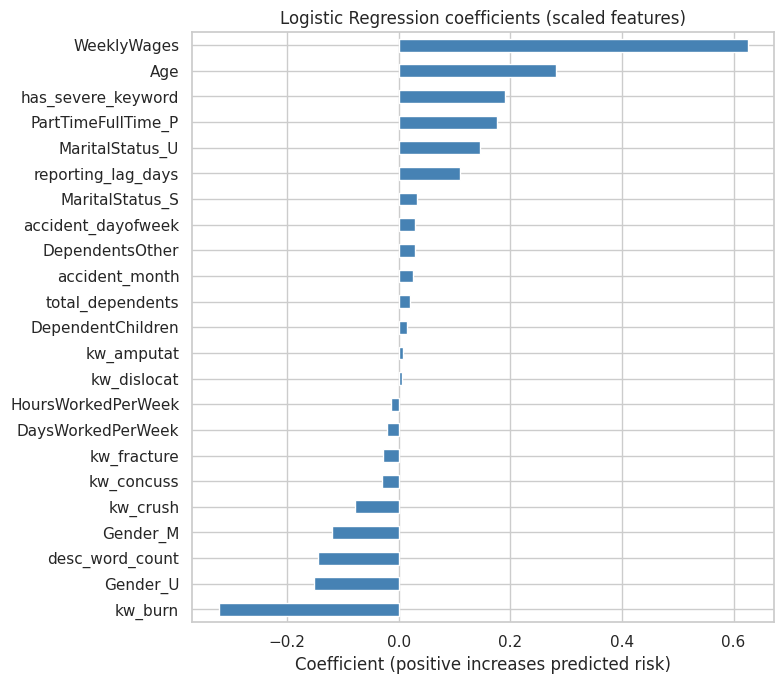

In [39]:
# Which features push a claim toward high risk, from the model coefficients
coefs = pd.Series(model.coef_[0], index=X.columns).sort_values()
plt.figure(figsize=(8, 7))
coefs.plot(kind="barh", color="steelblue")
plt.title("Logistic Regression coefficients (scaled features)")
plt.xlabel("Coefficient (positive increases predicted risk)")
plt.tight_layout()
plt.show()

## 11. Summary of findings

What the EDA showed:

- The final claim cost is heavy tailed. About 10 percent of claims account for the
  expensive outcomes, which is the group the triage system needs to flag early.
- The strongest early signals of a high risk claim are the presence of a severe
  injury keyword in the claim description, higher weekly wages, and a longer delay
  between the accident and the report.
- Full time status and older age are associated with a modestly higher risk.

Baseline model:

- A Logistic Regression model using only early features ranks high risk claims well
  above the random baseline (AUC around 0.73) and, with balanced class weights,
  recalls about two thirds of true high risk claims.
- Recall on the high risk class and AUC were chosen as the evaluation metrics
  because the problem is imbalanced and missing a high risk claim is more costly
  than a false alarm.
